# Planet Nine and the Cassini Ranging Data

*Matthew Payne*

If a planet several times the Earth's mass orbits a few hundred au from the Sun, its gravity pulls very slightly harder on the near side of the planetary system than on the far side. That *tidal* pull nudges Saturn off the orbit our ephemerides predict. For more than a decade, from 2004 to 2017, the Cassini spacecraft orbited Saturn, and radio ranging from Earth measured the Earth–Saturn distance to tens of metres. Could that ranging see Planet Nine?

This notebook repeats the analysis of

> M. J. Holman & M. J. Payne (2016), *Observational Constraints on Planet Nine: Cassini Range Observations*, AJ **152**, 94. [ADS](https://ui.adsabs.harvard.edu/abs/2016AJ....152...94H/abstract) · [arXiv:1604.03180](https://arxiv.org/abs/1604.03180)

(HP16), which built a simple, fast model of Planet Nine's effect on the Cassini range and used it to map, over the whole sky, how massive and how close a planet could be. We will:

1. Write down HP16's model: the tidal acceleration, Encke's method, and the part of the signal that a refit of Saturn's orbit absorbs.
2. Check it against the full ephemeris fits of Fienga et al. (2016) for a nominal Planet Nine orbit.
3. Map, over the sky, the largest tidal pull that 2004–2014 ranging at HP16's precision would have missed, and turn it into limits on Planet Nine's mass and distance.

One thing we cannot do: HP16 fitted the actual range residuals of Fienga et al. (2016), read from that paper's figures, and those residuals produced both their tightest limits and their preferred region of sky. We have only the measurement times, so we show what the data *could* detect, not what they did. Section 4 explains the difference.

**Requirements:** `numpy`, `scipy`, `matplotlib` and `requests` (for planet positions from JPL Horizons, cached in `data/`). **Run time:** under a minute.

In [1]:
import matplotlib.pyplot as plt
import numpy as np

import cassini as cs     # helper module in this folder

DEG = np.pi / 180
SIGMA = 31.95            # HP16's range uncertainty after rejecting outliers (m)
DCHI2_3SIG = 14.2        # 3 sigma for 3 parameters (two sky coordinates and the tidal strength), as in HP16

## 1. The model

**The tidal pull.** Planet Nine moves only a fraction of a degree in a decade, so over the Cassini mission it is effectively fixed. Its pull on Saturn *relative to the Sun* is the tidal acceleration

$$\vec F = \frac{G M_X}{r_X^3}\left[\vec r - 3\,(\vec r\cdot\hat n)\,\hat n\right]$$

(HP16 Eq. 7), where $\vec r$ is Saturn's heliocentric position, $M_X$ and $r_X$ are Planet Nine's mass and distance, and $\hat n$ points towards it. Only the combination $k = M_X/r_X^3$ and the direction $\hat n$ matter: a planet twice as far away and eight times as massive is indistinguishable.

**Encke's method.** Write Saturn's true position as its ephemeris position plus a small displacement, $\vec r = \vec\rho + \Delta\vec r$. To first order in $\Delta\vec r$,

$$\frac{d^2\Delta\vec r}{dt^2} = -\frac{\mu}{\rho^3}\left[\Delta\vec r - 3(\hat\rho\cdot\Delta\vec r)\,\hat\rho\right] + \vec F ,$$

with $\mu = G(M_\odot + M_{\rm Saturn})$. (HP16's Eq. 4 prints the $\Delta\vec r$ term with a plus sign; expanding $\mu(\vec\rho/\rho^3 - \vec r/r^3)$ gives the minus sign, as in Danby's textbook form of Encke's method.)

**What the ranging sees.** The Earth–Saturn distance changes by $\delta R = \hat R\cdot\Delta\vec r$, with $\hat R$ the unit vector from the Earth to Saturn. But the ephemeris that the residuals come from was *fitted* to the data: any part of $\delta R$ that a small change in Saturn's initial position and velocity could reproduce has already been absorbed. HP16 handle this by fitting those six numbers along with the perturbation; since everything is linear, we do the same with a least-squares projection. What survives is Planet Nine's *signature* in the range residuals.

**Linearity.** $\vec F$ is linear in the matrix $T = I - 3\hat n\hat n^{\rm T}$, which has six independent entries. So we integrate the equation six times, once for each entry, and the signature for any direction and any $k$ is a weighted sum of those six. That is what makes the all-sky maps below fast.

The positions of Saturn (the barycentre of its system) and the Earth come from JPL Horizons, in the equatorial ICRF frame. The measurement times are approximate: HP16 do not list them, so `tools/derive_cassini_times.py` reads their distribution off HP16's Figure 1, giving about 190 times between late 2004 and mid-2014.

In [2]:
jd, sat = cs.horizons_vectors("6", "2004-01-01", "2015-01-01", "1 d", "data/saturn_2004_2015.npz")
_, ear = cs.horizons_vectors("399", "2004-01-01", "2015-01-01", "1 d", "data/earth_2004_2015.npz")
eph = cs.Ephemeris(jd, sat, ear)
t_obs = np.loadtxt("data/range_times.csv", comments="#", skiprows=3)
years = 2004 + (t_obs - cs.JD_2004) / 365.25
forced, free = cs.responses(eph, t_obs, t_obs[0])
P = cs.projector(free)
forced_perp = forced @ P.T          # the six basis signatures, after the refit
print(f"{len(t_obs)} measurement times, {years[0]:.2f} to {years[-1]:.2f}; smallest solar elongation {eph.elongation(t_obs).min():.0f}°")
print(f"Fraction of the raw signal the refit absorbs, per basis component: {1 - np.linalg.norm(forced_perp, axis=1) / np.linalg.norm(forced, axis=1)}")

190 measurement times, 2004.75 to 2014.34; smallest solar elongation 1°
Fraction of the raw signal the refit absorbs, per basis component: [0.97066257 0.88340018 0.82145524 0.80937869 0.86505716 0.85431003]


The refit absorbs most of the raw displacement, between 80% and 97% depending on the direction of the pull: over ten years, most of what a nearly constant extra pull does to Saturn looks just like a slightly different orbit. Only what remains can betray Planet Nine, which is why the precision of the ranging matters so much.

## 2. Checking against a full ephemeris fit

Fienga et al. (2016) added a 10-Earth-mass Planet Nine to their INPOP planetary ephemeris, on the nominal orbit of Batygin & Brown (2016) ($a = 700$ au, $e = 0.6$, $i = 30°$, $\Omega = 113°$, $\omega = 150°$, ecliptic), refitted all of their ephemeris parameters to all of their data, and repeated this for a range of positions (true anomalies $\nu$) along the orbit. HP16's Figure 1 shows how the Cassini residuals changed for $\nu$ = 60°, 70°, 85°, 90° and 95°, and HP16's model reproduced those changes. Here is ours.

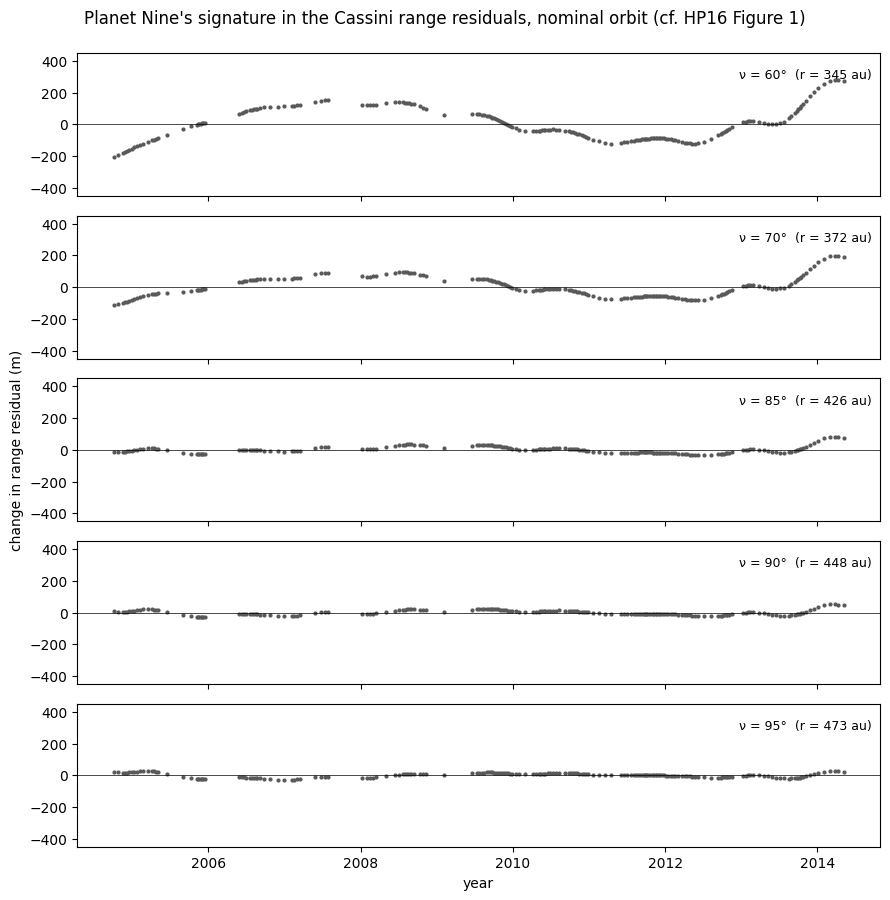

ν = 60°: signature from -204 to 278 m, RMS 103 m
ν = 70°: signature from -112 to 198 m, RMS 64 m


In [3]:
def nominal(nu_deg, mass=10 * cs.M_EARTH):
    pos = cs.ecliptic_orbit_position(700, 0.6, 30 * DEG, 113 * DEG, 150 * DEG, np.radians(nu_deg))
    r = np.linalg.norm(pos, axis=-1)
    return pos / r[..., None], mass / r**3, r

fig, axs = plt.subplots(5, 1, figsize=(9, 9), sharex=True, sharey=True)
for ax, nu in zip(axs, [60, 70, 85, 90, 95]):
    n, k, r = nominal(nu)
    s = cs.signature(n, k, forced_perp)
    ax.plot(years, s, ".", color="0.35", ms=4)
    ax.axhline(0, color="k", lw=0.5)
    ax.text(0.99, 0.82, f"ν = {nu}°  (r = {r:.0f} au)", transform=ax.transAxes, ha="right", fontsize=9)
    ax.set_ylim(-450, 450)
axs[2].set_ylabel("change in range residual (m)")
axs[-1].set_xlabel("year")
fig.suptitle("Planet Nine's signature in the Cassini range residuals, nominal orbit (cf. HP16 Figure 1)", y=0.995)
fig.tight_layout()
plt.show()
for nu in (60, 70):
    n, k, r = nominal(nu)
    s = cs.signature(n, k, forced_perp)
    print(f"ν = {nu}°: signature from {s.min():.0f} to {s.max():.0f} m, RMS {np.sqrt(np.mean(s**2)):.0f} m")

The signatures have the same shapes as the changes Fienga et al. found (HP16 Figure 1). At $\nu$ = 60°, the residuals start about 200 m low in 2004, rise to a broad hump in 2007–2008, dip in 2011–2012 and climb steeply through 2014; by $\nu$ = 85°–95° the signature is down to a few tens of metres. Ours are about a quarter smaller than theirs at $\nu$ = 60° (their changes reach roughly −300 and +350 m); our approximate measurement times are one possible reason, and we have not tracked the difference down. For so simple a model the agreement is close, as HP16 found.

How strongly would each position along this orbit show up? With uncorrelated errors of $\sigma$ = 32 m, a signature $s_i$ that is *not* in the data would raise the best-fit $\chi^2$ by about $\sum_i s_i^2/\sigma^2$. That is the expected $\Delta\chi^2$ if Planet Nine were really at that position and the ranging had not seen it.

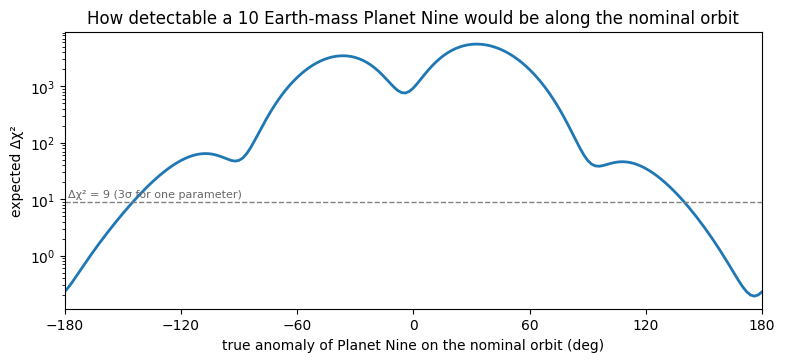

Expected Δχ² above 9 for ν from -144° to 138° (Planet Nine closer than about 871 au); below 9 nearer aphelion


In [4]:
nus = np.arange(-180, 181, 2)
n, k, r = nominal(nus)
d2 = np.array([np.sum(cs.signature(nn, kk, forced_perp)**2) for nn, kk in zip(n, k)]) / SIGMA**2
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.semilogy(nus, d2, color="C0", lw=2)
ax.axhline(9, color="0.5", ls="--", lw=1)
ax.text(-178, 11, "Δχ² = 9 (3σ for one parameter)", fontsize=8, color="0.4")
ax.set(xlabel="true anomaly of Planet Nine on the nominal orbit (deg)", ylabel="expected Δχ²", xlim=(-180, 180), xticks=range(-180, 181, 60))
ax.set_title("How detectable a 10 Earth-mass Planet Nine would be along the nominal orbit")
plt.show()
strong = nus[d2 >= 9]
print(f"Expected Δχ² above 9 for ν from {strong.min()}° to {strong.max()}° (Planet Nine closer than about "
      f"{nominal(np.array([strong.min(), strong.max()]))[2].max():.0f} au); below 9 nearer aphelion")

Near pericentre, Planet Nine would be only 280 au away and its signature enormous; near aphelion, 1,100 au away, it is too weak to see. Fienga et al. (2016) excluded much of the orbit, including the part around pericentre, and found that their fit *improved* with Planet Nine at $\nu \approx 117°$ (the best fit shown in HP16's Figure 1), where the expected signal is modest. An improvement like that cannot come from the model alone: it means the actual residuals happen to contain something resembling the signature. We return to this in Section 4.

## 3. The whole sky

Now forget the nominal orbit and put a tidal perturber anywhere on the sky. For each direction, the signature is linear in $k$, so the expected $\Delta\chi^2$ grows as $k^2$, and we can solve for the $k$ at which it reaches HP16's 3σ threshold, $\Delta\chi^2 = 14.2$. A perturber stronger than that would have been seen. (The tidal pattern is symmetric: a perturber at $\hat n$ and one at $-\hat n$ pull identically, so every map has two equal halves.)

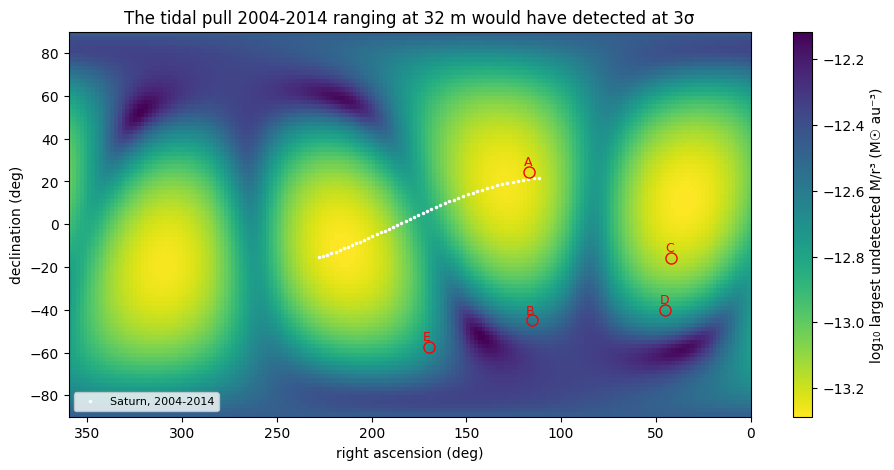

Undetectable below M/r³ = 5.2e-14 to 7.7e-13 M☉/au³; area-weighted median 1.2e-13


In [5]:
ra_g = np.arange(1, 360, 2) * DEG
dec_g = np.arange(-89, 90, 2) * DEG
RA, DEC = np.meshgrid(ra_g, dec_g)
N = cs.radec_to_unit(RA.ravel(), DEC.ravel())
C = np.array([cs.tensor_coeffs(v) for v in N])                    # (npix, 6)
amp = np.linalg.norm(C @ forced_perp, axis=1) * cs.AU_M          # signature RMS*sqrt(N) for k = 1, in m
k_lim = (np.sqrt(DCHI2_3SIG) * SIGMA / amp).reshape(RA.shape)

sat_now = eph.saturn(np.linspace(t_obs[0], t_obs[-1], 50))
sat_ra = np.degrees(np.arctan2(sat_now[:, 1], sat_now[:, 0])) % 360
sat_dec = np.degrees(np.arcsin(sat_now[:, 2] / np.linalg.norm(sat_now, axis=1)))

fig, ax = plt.subplots(figsize=(11, 5))
im = ax.pcolormesh(np.degrees(ra_g), np.degrees(dec_g), np.log10(k_lim), cmap="viridis_r", shading="nearest")
ax.plot(sat_ra, sat_dec, "w.", ms=3, label="Saturn, 2004-2014")
for name, ra_d, dec_d in [("A", 116.7, 24.6), ("B", 115.5, -45.0), ("C", 42.2, -15.7), ("D", 45.0, -40.2), ("E", 169.8, -57.4)]:
    ax.plot(ra_d, dec_d, "o", mfc="none", mec="r", ms=8)
    ax.text(ra_d + 3, dec_d + 3, name, color="r", fontsize=9)
ax.set(xlabel="right ascension (deg)", ylabel="declination (deg)", xlim=(360, 0), ylim=(-90, 90))
fig.colorbar(im, ax=ax, label="log₁₀ largest undetected M/r³ (M☉ au⁻³)")
ax.legend(loc="lower left", fontsize=8)
ax.set_title("The tidal pull 2004-2014 ranging at 32 m would have detected at 3σ")
plt.show()
w = np.cos(DEC).ravel()
print(f"Undetectable below M/r³ = {k_lim.min():.1e} to {k_lim.max():.1e} M☉/au³; "
      f"area-weighted median {np.median(np.repeat(k_lim.ravel(), np.round(10 * w).astype(int))):.1e}")

The ranging is most sensitive, with limits near $5\times10^{-14}\,M_\odot\,{\rm au}^{-3}$, over four broad regions of sky, and least sensitive, near $10^{-12}$, along narrow curved bands where Planet Nine's pull over these ten years happens to resemble a small change of Saturn's orbit, which the refit absorbs. Over half the sky the limit is about $10^{-13}$: a 10-Earth-mass planet at about 630 au.

What does a limit on $M/r^3$ mean for a planet? For a given mass, it is a minimum distance:

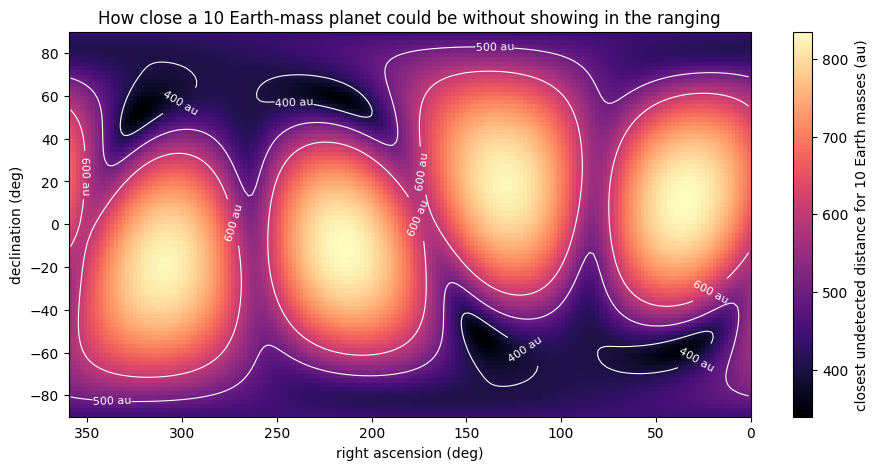

A 10 Earth-mass planet closer than 340-835 au (depending on direction) would have been detected; for 5 Earth masses the distances shrink by a factor 1.26.


In [6]:
fig, ax = plt.subplots(figsize=(11, 5))
r_min = (10 * cs.M_EARTH / k_lim) ** (1 / 3)
im = ax.pcolormesh(np.degrees(ra_g), np.degrees(dec_g), r_min, cmap="magma", shading="nearest")
cs_ = ax.contour(np.degrees(ra_g), np.degrees(dec_g), r_min, levels=[300, 400, 500, 600], colors="w", linewidths=0.8)
ax.clabel(cs_, fmt="%d au", fontsize=8)
ax.set(xlabel="right ascension (deg)", ylabel="declination (deg)", xlim=(360, 0), ylim=(-90, 90))
fig.colorbar(im, ax=ax, label="closest undetected distance for 10 Earth masses (au)")
ax.set_title("How close a 10 Earth-mass planet could be without showing in the ranging")
plt.show()
print(f"A 10 Earth-mass planet closer than {r_min.min():.0f}-{r_min.max():.0f} au (depending on direction) would have been detected; "
      f"for 5 Earth masses the distances shrink by a factor {2 ** (1 / 3):.2f}.")

## 4. What the residuals add

HP16's limits are tighter than these, about $10^{-14}\,M_\odot\,{\rm au}^{-3}$ over large areas of sky, and they also found a preferred region, around RA 40°, Dec −15° (and the opposite point of the sky). Both come from the residuals themselves. With real residuals $d_i$, adding the perturbation changes the best fit's $\chi^2$ by

$$\Delta\chi^2(k) = \frac{k^2\sum_i s_i^2 - 2k\sum_i s_i d_i}{\sigma^2},$$

where $s_i$ is the signature for unit $k$. The first term is the one mapped above. The second, linear in $k$, depends on how the residuals happen to line up with each signature: where they line up, adding a perturber *improves* the fit, giving the minima of HP16's Figure 7 and the preferred region; where they are anti-aligned, $\chi^2$ rises faster than the first term alone and the limits tighten. At large $k$ the first term always wins, so we can check our model against HP16's Figure 7 there.

A (116.7, 24.6)    expected Δχ² at k = 1e-12:    4176;  3σ limit 5.8e-14 M☉/au³
B (115.5, -45.0)   expected Δχ² at k = 1e-12:     229;  3σ limit 2.5e-13 M☉/au³
C (42.2, -15.7)    expected Δχ² at k = 1e-12:    3167;  3σ limit 6.7e-14 M☉/au³
D (45.0, -40.2)    expected Δχ² at k = 1e-12:     611;  3σ limit 1.5e-13 M☉/au³
E (169.8, -57.4)   expected Δχ² at k = 1e-12:     366;  3σ limit 2.0e-13 M☉/au³


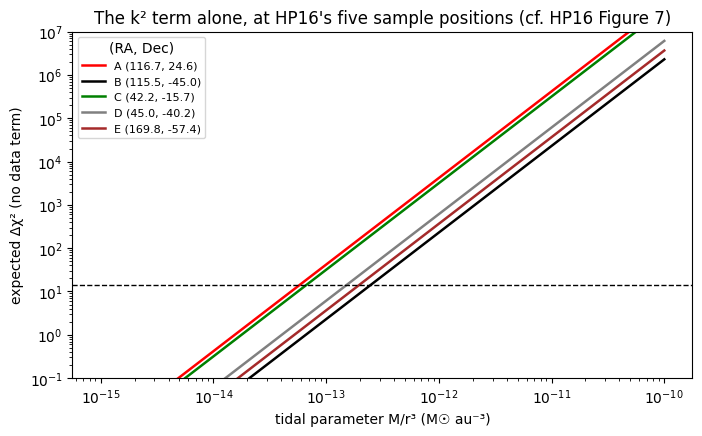

In [7]:
ks = np.logspace(-15, -10, 60)
fig, ax = plt.subplots(figsize=(8, 4.5))
for (name, ra_d, dec_d), col in zip([("A (116.7, 24.6)", 116.7, 24.6), ("B (115.5, -45.0)", 115.5, -45.0), ("C (42.2, -15.7)", 42.2, -15.7),
                                     ("D (45.0, -40.2)", 45.0, -40.2), ("E (169.8, -57.4)", 169.8, -57.4)], ["r", "k", "g", "0.5", "brown"]):
    n = cs.radec_to_unit(ra_d * DEG, dec_d * DEG)
    q = np.sum(cs.signature(n, 1.0, forced_perp)**2) / SIGMA**2
    ax.loglog(ks, q * ks**2, color=col, lw=1.8, label=name)
    print(f"{name:18s} expected Δχ² at k = 1e-12: {q * 1e-24:7.0f};  3σ limit {np.sqrt(DCHI2_3SIG / q):.1e} M☉/au³")
ax.axhline(DCHI2_3SIG, color="k", ls="--", lw=1)
ax.set(xlabel="tidal parameter M/r³ (M☉ au⁻³)", ylabel="expected Δχ² (no data term)", ylim=(0.1, 1e7))
ax.legend(fontsize=8, title="(RA, Dec)")
ax.set_title("The k² term alone, at HP16's five sample positions (cf. HP16 Figure 7)")
plt.show()

At large $k$, HP16's curves in their Figure 7 follow this $k^2$ term. Extrapolating them back from $k = 10^{-10}$ gives $\Delta\chi^2 \approx 6{,}000$ at A and $\approx 250$ at B for $k = 10^{-12}$, against our 4,200 and 230: the sizes of the signatures agree to about 20%.

At smaller $k$, HP16's curves part company with ours, because of the linear term. At A and B the residuals push $\Delta\chi^2$ up, and HP16 rule out perturbers there above about $5\times10^{-15}$ and $2\times10^{-14}$, roughly ten times below the limits from the $k^2$ term alone ($5.8\times10^{-14}$ and $2.5\times10^{-13}$). At C, D and E the residuals pull $\Delta\chi^2$ down instead, to minima of about −150 near $k \approx 2$–$6\times10^{-13}$: these are HP16's preferred locations. Without the residuals we can reproduce neither effect, only the sensitivity they act on.

## Summary

* A distant planet's effect on Saturn is a tidal acceleration fixed by two things only, the direction to the planet and $M/r^3$; Encke's method turns it into a change in the Earth–Saturn range, and a refit of Saturn's orbit absorbs 80–97% of that change.
* This simple linear model reproduces the shapes of the full ephemeris fits of Fienga et al. (2016) for the nominal Planet Nine orbit, with amplitudes about a quarter smaller, and matches HP16's own model to about 20%.
* Ranging over 2004–2014 at 32 m precision would detect, at 3σ, a tidal parameter above $5\times10^{-14}$ to $8\times10^{-13}\,M_\odot\,{\rm au}^{-3}$, depending on direction: a 10-Earth-mass planet closer than 340–840 au.
* HP16's tighter limits and their preferred region come from how the actual residuals line up with each signature, which needs the residuals themselves.

## Going further

* **The residuals.** With the actual range residuals, the linear term could be added and HP16's preferred region recovered. Fienga et al. (2016) and later INPOP releases describe the Cassini data; the full fit also needs the Earth's own tidal perturbation, which HP16 neglect.
* **Longer arcs.** Cassini ranged until 2017. Because the refit absorbs so much, the sensitivity grows steeply with the length of the arc: try extending the times in `data/range_times.csv` and see how the limits move.
* **Other planets.** The same tidal model applies to Jupiter (Juno) or Mars (orbiters and landers), whose ranging is even more precise, though over shorter distances from Planet Nine's tide.

## References

* Batygin, K. & Brown, M. E. 2016, *Evidence for a Distant Giant Planet in the Solar System*, AJ 151, 22. [ADS](https://ui.adsabs.harvard.edu/abs/2016AJ....151...22B/abstract)
* Danby, J. M. A. 1992, *Fundamentals of Celestial Mechanics*, 2nd ed. (Willmann-Bell). [ADS](https://ui.adsabs.harvard.edu/abs/1992fcm..book.....D/abstract)
* Fienga, A., Laskar, J., Manche, H. & Gastineau, M. 2016, *Constraints on the location of a possible 9th planet derived from the Cassini data*, A&A 587, L8. [ADS](https://ui.adsabs.harvard.edu/abs/2016A%26A...587L...8F/abstract)
* Holman, M. J. & Payne, M. J. 2016, *Observational Constraints on Planet Nine: Cassini Range Observations*, AJ 152, 94. [ADS](https://ui.adsabs.harvard.edu/abs/2016AJ....152...94H/abstract)